In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [19]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Literal, List  ###Literal will allow us to select within our options categories

##Libraries for agents
from langchain_community.utilities import GoogleBooksAPIWrapper
from langchain.agents import create_agent
from langchain.tools import tool

In [20]:
class FlowState(BaseModel):
    question:str= Field(description="user's question")
    category:Literal["coding", "google_search", "weather"]=Field(default="google_search")
    answer:str=Field(default="")

In [21]:
class QuestionCategory(BaseModel):
    category:Literal["coding", "google_search", "weather"]=Field(default="google_search", description="question category")

    

In [22]:
llm=ChatGroq(model="llama-3.3-70b-versatile")

In [ ]:
search=GoogleBooksAPIWrapper(serper_api_key="0c9fb20f81243147ab43b8db173fad790b0a80b9")
tools=[search.run]

google_agent=create_agent(
    model=llm,
    tools=tools,
    system_prompt="You are a agent and can search for any question from Google"
)

#weather agent

@tool
def get_weather(city:str):
    """ It provide real time weather details for any city"""
    return f"The current temperature in {city} is 25.C"

weather_agent=create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a agent and can provide real time weather details"
)

In [9]:
def CheckQuestionCategory(state:FlowState)->FlowState:
    st_llm=llm.with_structured_output(QuestionCategory) ###LLM will give output in the form of QuestionCategory object's with structure
    res=st_llm.invoke(f"I want to know about the category of the question, question is {state.question}, if you are not sure then just select 'google-search' as category ")
    state.category=res.category

    return state

In [10]:
def route(state:FlowState)->Literal["coding", "google_search", "weather"]:
    return state.category

In [18]:
def coding_node(state:FlowState)->FlowState:
    res=llm.invoke(f"you are coding expert{state.question}")
    state.answer=res.content
    return state

def weather_node(state:FlowState)->FlowState:
    res=weather_agent.invoke({"messages":[
        {"role":"user", "content":state.question}
    ]})
    state.answer=res["messages"][-1].content
    return state

def google_search_node(state:FlowState)->FlowState:
    res=google_agent.invoke({"messages":[
            {"role":"user", "content":state.question}
        ]})
    state.answer=res["messages"][-1].content
    return state

In [13]:
graph=StateGraph(FlowState)

graph.add_node("CheckQuestionCategory", CheckQuestionCategory)
graph.add_node("coding", coding_node)
graph.add_node("weather", weather_node)
graph.add_node("google_search", google_search_node)

graph.add_edge(START, "CheckQuestionCategory")
graph.add_conditional_edges("CheckQuestionCategory", route)
graph.add_edge("coding", END)
graph.add_edge("weather", END)
graph.add_edge("google_search", END)

graph=graph.compile()


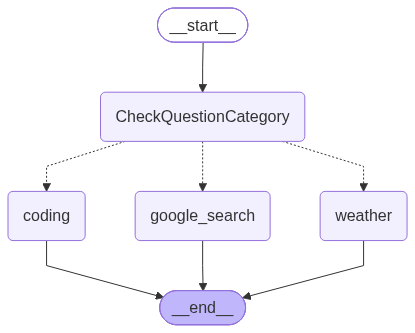

In [15]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [ ]:
response=graph.invoke({"question: what is the temperature in Shimla ?"})